# 🧭 ШПАРГАЛКА: что менять при смене датасета / темы

Этот ноутбук рассчитан на **классификацию изображений** (любой датасет: знаки, одежда, цветы, лица, рентген…). Всё, что зависит от задачи, собрано в **двух местах**. Всё остальное трогать не нужно.

| № | Где | Что менять |
|---|---|---|
| 1 | **Ячейка `CONFIG`** (сразу ниже) | `DATA_SOURCE`, пути, `IMG`, `N_TRAIN`, `MODEL_KIND`, `EPOCHS`, `USE_HFLIP`, силу аугментаций |
| 2 | **Ячейка «Загрузка датасета»** (функция `make_datasets`) | для `DATA_SOURCE="torchvision"` — какой датасет и аргументы `train=`/`split=` (смотри доку) |
| 3 | **Ячейка «Аугментации»** | решение: безопасен ли flip / сильный поворот для *этих* классов (`USE_HFLIP`) |
| 4 | **Part D** | если эксперимент в задании другой (не дисбаланс) — шаблон в конце Part D |

Места, где нужна правка, помечены в коде значком **🔧 ИЗМЕНИ**.

**Чего этот ноутбук НЕ делает:** детекцию объектов (боксы), сегментацию, регрессию. Если тема такая — это другой код.

**Порядок:** прогоняй ячейки строго сверху вниз. После каждой ячейки кода есть блок **«🔍 Разбор»**.

# 0. Азбука «с нуля» (прочитай один раз)

**Картинка для компьютера.** Цветная картинка 48×48 — это 3 матрицы (каналы R, G, B) 48×48 с числами 0–255. В PyTorch это тензор `[3, 48, 48]`; пачка (**batch**) — `[B, 3, 48, 48]`.

**Классификация.** Модель берёт картинку и выдаёт K чисел (**логиты**) — по одному на класс. `argmax` по ним = предсказанный класс.

**Кирпичики CNN:**
- **Conv2d (свёртка)** — маленький фильтр 3×3 скользит по картинке и ищет паттерн (край, угол, цвет). Ранние слои видят края, глубокие — формы объектов.
- **BatchNorm** — нормирует значения внутри батча → обучение быстрее и стабильнее.
- **ReLU** = `max(0, x)` — нелинейность; без неё стопка слоёв = одна линейная функция.
- **MaxPool 2×2** — из каждого квадрата 2×2 берёт максимум → карта вдвое меньше, больше устойчивости к сдвигам.
- **Global Average Pooling (GAP)** — каждую карту признаков усредняет в одно число. Вместо огромного полносвязного слоя → мало параметров, и сеть работает с любым размером картинки.
- **Linear** — финальный слой: вектор признаков → K логитов.
- **Dropout** — при обучении случайно выключает часть нейронов → меньше переобучения.

**Обучение.** Батч → предсказание → **loss** (CrossEntropy) → `backward()` считает градиенты → **оптимизатор** (Adam) меняет веса. **Эпоха** = один проход по всем обучающим картинкам.

**Train / Val / Test.** *train* — учим; *val* — выбираем лучшую эпоху/настройки; *test* — трогаем в конце, честная оценка. **Переобучение** — на train почти идеально, на val/test заметно хуже.

**Метрики** (для класса c):
- `true_c` — сколько картинок реально класса c; `predicted_c` — сколько модель назвала c; `correct_c` — сколько угадала.
- **recall_c = correct_c / true_c**  (из реальных c — сколько нашли)
- **precision_c = correct_c / predicted_c**  (из названных c — сколько правда c)
- **F1_c = 2·precision·recall / (precision + recall)**
- **accuracy = верных ответов / всех картинок**
- **macro-F1** = простое среднее F1 по всем классам (каждый класс весит одинаково → замечает провал на редких классах).
- **Confusion matrix:** строка = истинный класс (сумма строки = `true_c`), столбец = предсказанный (сумма столбца = `predicted_c`), диагональ = `correct_c`.

**Дисбаланс классов.** Одних классов в данных в разы больше других → модели выгодно хорошо знать частые и «забить» на редкие.

**Аугментация.** Случайные искажения *только обучающих* картинок на лету. Правило: искажение обязано **сохранять смысл класса**.

# ⚙️ CONFIG — главный пульт управления

Меняешь значения здесь — весь ноутбук подстраивается. Каждый параметр объяснён в комментарии.

In [7]:
# ============================ 🔧 CONFIG ============================
TASK_NAME   = "Satellite Land-Use Classifier"   # 🔧 название проекта (для заголовков)

# ---------- откуда берём данные ----------
DATA_SOURCE = "torchvision"   # 🔧 "torchvision" (готовый датасет) | "folder" (папки по классам)
                              #    | "csv" (папка картинок + CSV с метками) | "npz" (.npz файл с массивами)
DATA_ROOT   = "data"          # 🔧 куда качать / где лежат данные (можно путь в Google Drive)
USE_DRIVE   = False           # 🔧 True -> подключить Google Drive в следующей ячейке

# --- настройки для DATA_SOURCE = "folder" ---
FOLDER_TRAIN = "data/train"   # 🔧 папка, внутри которой подпапки-классы: data/train/cat/*.jpg ...
FOLDER_TEST  = None           # 🔧 папка теста в таком же формате; None = отрезать часть от train (TEST_FRAC)

# --- настройки для DATA_SOURCE = "csv" ---
CSV_PATH      = "data/labels.csv"   # 🔧 CSV с метками
CSV_IMG_DIR   = "data/images"       # 🔧 папка с картинками
CSV_COL_FILE  = "filename"          # 🔧 название колонки с именем файла
CSV_COL_LABEL = "label"             # 🔧 название колонки с классом (число или текст)
CSV_SEP       = ","                 # 🔧 разделитель (иногда ";")

# --- настройки для DATA_SOURCE = "npz" ---
NPZ_PATH    = "data/dataset.npz"    # 🔧 путь к .npz
NPZ_X_TRAIN, NPZ_Y_TRAIN = "x_train", "y_train"   # 🔧 ключи внутри файла (смотри: np.load(path).files)
NPZ_X_TEST,  NPZ_Y_TEST  = "x_test",  "y_test"    # 🔧 ключи теста; поставь None, если теста нет

# ---------- размеры выборок ----------
IMG       = 64        # 🔧 размер картинки после resize (IMG x IMG); минимум 8
N_TRAIN   = 5600      # 🔧 сколько картинок брать для обучения; None = все
N_VAL     = 1200      # 🔧 размер валидации (отрезается от train)
TEST_FRAC = 0.04      # 🔧 доля теста, ТОЛЬКО если готового теста нет
CLASS_NAMES_OVERRIDE = None   # 🔧 свой список названий классов, если датасет их не даёт: ["cat", "dog", ...]

# ---------- модель и обучение ----------
MODEL_KIND = "resnet18"    # 🔧 "own" (своя CNN) | "resnet18" | "mobilenet_v2"
PRETRAINED = True    # 🔧 True -> брать предобученные веса ImageNet (для resnet18 / mobilenet_v2; нужен интернет)
BATCH  = 128          # 🔧 размер батча (если мало памяти GPU — уменьши до 64 / 32)
EPOCHS = 15           # 🔧 число эпох (мало времени -> 8-10)
LR     = 1e-3         # 🔧 скорость обучения (для fine-tuning предобученной: 3e-4)

# ---------- аугментации ----------
USE_HFLIP      = True   # 🔧 горизонтальный flip: True только если зеркало НЕ меняет класс (см. разбор ниже)
AUG_ROTATION   = 90      # 🔧 макс. поворот в градусах
AUG_TRANSLATE  = 0.1     # 🔧 макс. сдвиг (доля размера)
AUG_SCALE      = (0.9, 1.1)   # 🔧 масштаб от..до
AUG_BRIGHTNESS = 0.2     # 🔧 сила случайной яркости
AUG_CONTRAST   = 0.2     # 🔧 сила случайного контраста

# ---------- прочее ----------
SEED = 42
NUM_WORKERS = 2          # 🔧 если ошибка DataLoader (бывает на Windows) -> 0

### 🔍 Разбор
- Это просто переменные (константы), которые читают ячейки ниже. Если ты поменял значение — **перезапусти ноутбук сверху** (Runtime → Run all), иначе функции, определённые раньше, могут держать старое значение.
- **`DATA_SOURCE`** выбирает ветку загрузки данных. Настройки для неактивных веток игнорируются — можно оставлять как есть.
- **`IMG`**: чем больше, тем точнее, но медленнее. Для мелких картинок (MNIST 28×28, CIFAR 32×32) хватит 32; для знаков/лиц 48–64; для предобученных моделей лучше 64–96.
- **`N_TRAIN`**: в экзамене сказано «about 10,000» — это для скорости. `None` берёт весь train.
- **`MODEL_KIND` / `PRETRAINED`**: условие экзамена — своя CNN (≥3 conv-блока) *или* дообученный MobileNetV2/ResNet-18. Оба варианта здесь переключаются одной строкой.
- **`USE_HFLIP`** — самое «смысловое» решение, о нём подробно в разборе ячейки «Аугментации».

In [ ]:
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    # 🔧 после подключения пути к данным будут вида "/content/drive/MyDrive/<твоя папка>/..."
    # 🔧 если данные лежат в zip на Drive, раскомментируй (и поправь пути):
    # !unzip -q "/content/drive/MyDrive/data.zip" -d /content/data
    # !wget -q <ССЫЛКА> -O data.zip && unzip -q data.zip -d data     # скачать по прямой ссылке
    # !pip install -q gdown && gdown --fuzzy "<ССЫЛКА_GOOGLE_DRIVE>"  # общий файл с Google Drive

### 🔍 Разбор
- Ячейка нужна, только если данные лежат на Google Drive. `drive.mount` откроет окно авторизации; после этого Drive виден как папка `/content/drive/MyDrive`.
- Закомментированные строки — шпаргалка: `!unzip` (распаковать), `!wget` (скачать по ссылке), `gdown` (скачать общий файл из Drive). Строки с `!` — это shell-команды внутри Colab.
- Если `USE_DRIVE = False`, ячейка ничего не делает.

In [3]:
import os, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (будет медленно!)")
assert IMG >= 8, "IMG должен быть >= 8 (иначе три MaxPool сожмут картинку в ноль)"

device: cuda | Tesla T4


### 🔍 Разбор
- **Импорты.** `numpy` — массивы; `pandas` — таблицы; `matplotlib` — графики; `cv2` (OpenCV) — resize и искажения в Part E; `PIL.Image` — формат картинок torchvision; `torch`/`nn` — нейросеть; `Dataset, DataLoader` — подача данных батчами; `WeightedRandomSampler` — oversampling (Part D); `sklearn.metrics` — метрики.
- **`set_seed`** фиксирует все генераторы случайных чисел → воспроизводимость и честное сравнение экспериментов.
- **`device`**: GPU (Runtime → Change runtime type → GPU) на порядки быстрее CPU. Если напечатано `CPU` — включи GPU, иначе обучение займёт часы.
- **`assert IMG >= 8`** — защита от ошибки: после трёх MaxPool картинка уменьшается в 8 раз.

# Part A — Data pipeline [15 pts]

**Нужно:** загрузить данные → распределение классов → resize + normalize → безопасные аугментации (объяснить, почему flip подходит/не подходит) → показать 8 примеров с метками.

In [4]:
from torchvision.datasets import EuroSAT
ds = EuroSAT(root="data", download=True)
print(ds.classes)         # список названий
print(ds.class_to_idx)    # словарь название -> индекс

100%|██████████| 94.3M/94.3M [00:00<00:00, 95.4MB/s]


['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
{'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}


In [8]:
# ---------- вспомогательные Dataset-классы для нестандартных источников ----------
class CsvImageDataset(Dataset):
    # Папка картинок + CSV (имя файла, класс). Метки-строки автоматически превращаются в числа 0..K-1.
    def __init__(self, csv_path, img_dir, col_file, col_label, sep=","):
        df = pd.read_csv(csv_path, sep=sep)
        self.files = df[col_file].astype(str).tolist()
        raw = df[col_label].tolist()
        try:    uniq = sorted(set(raw))
        except TypeError: uniq = sorted(set(raw), key=str)
        to_idx = {c: i for i, c in enumerate(uniq)}
        self.targets = [to_idx[r] for r in raw]
        self.classes = [str(c) for c in uniq]
        self.img_dir = img_dir
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        return Image.open(os.path.join(self.img_dir, self.files[i])), self.targets[i]

class ArrayDataset(Dataset):
    # Готовые массивы картинок X (N,H,W[,C]) и меток y (N,)
    def __init__(self, X, y):
        self.X, self.y = X, np.asarray(y).astype(np.int64).reshape(-1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return self.X[i], int(self.y[i])

def to_rgb_uint8(x):
    # Любая картинка (PIL / numpy / тензор; серая / цветная / с альфой; float / uint8) -> (H, W, 3) uint8 RGB
    if isinstance(x, Image.Image):                       # PIL
        return np.array(x.convert("RGB"))
    if isinstance(x, torch.Tensor):                      # тензор
        x = x.detach().cpu().numpy()
        if x.ndim == 3 and x.shape[0] in (1, 3):         # (C,H,W) -> (H,W,C)
            x = x.transpose(1, 2, 0)
    x = np.asarray(x)
    if x.dtype != np.uint8:                              # float -> uint8
        x = (x * 255) if x.max() <= 1.0 else x
        x = x.clip(0, 255).astype(np.uint8)
    if x.ndim == 2:                                      # серая без канала
        x = x[..., None]
    if x.shape[-1] == 1:                                 # 1 канал -> 3
        x = np.repeat(x, 3, axis=-1)
    return x[..., :3]                                    # отрезаем альфа-канал, если есть

GTSRB_CLASS_NAMES = [
    'AnnualCrop', 'Forest', 'HerbaceousVegetation',
    'Highway', 'Industrial', 'Pasture', 'PermanentCrop',
    'Residential', 'River', 'SeaLake',
]

def make_datasets():
    # Возвращает (train_ds, test_ds). test_ds может быть None -> тогда тест отрежем от train.
    # Любой ds должен давать ds[i] -> (картинка, номер_класса) и иметь len(ds).
    if DATA_SOURCE == "torchvision":
        # 🔧 ИЗМЕНИ ЭТИ ДВЕ СТРОКИ под свой датасет. Как выбирается train/test — смотри в доке
        #    torchvision.datasets.<Имя> (у одних train=True/False, у других split="train"/"test").
        #train = datasets.GTSRB(root=DATA_ROOT, split="train", download=True)
       # test  = datasets.GTSRB(root=DATA_ROOT, split="test",  download=True)
        # --- примеры (раскомментируй нужное, старое закомментируй; сверяй аргументы с докой!) ---
        # FashionMNIST / MNIST:  train = datasets.FashionMNIST(DATA_ROOT, train=True,  download=True)
        #                        test  = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
        # CIFAR10 / CIFAR100:    train = datasets.CIFAR10(DATA_ROOT, train=True,  download=True)
        #                        test  = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
        # STL10 / SVHN:          train = datasets.STL10(DATA_ROOT, split="train", download=True)
        #                        test  = datasets.STL10(DATA_ROOT, split="test",  download=True)
        # Flowers102:            train = datasets.Flowers102(DATA_ROOT, split="train", download=True)
        #                        test  = datasets.Flowers102(DATA_ROOT, split="test",  download=True)
        train = datasets.EuroSAT(DATA_ROOT, download=True);  test = None
        return train, test
    if DATA_SOURCE == "folder":
        train = datasets.ImageFolder(FOLDER_TRAIN)                       # классы = имена подпапок
        test  = datasets.ImageFolder(FOLDER_TEST) if FOLDER_TEST else None
        return train, test
    if DATA_SOURCE == "csv":
        return CsvImageDataset(CSV_PATH, CSV_IMG_DIR, CSV_COL_FILE, CSV_COL_LABEL, CSV_SEP), None
    if DATA_SOURCE == "npz":
        d = np.load(NPZ_PATH)
        print("keys in npz:", d.files)
        train = ArrayDataset(d[NPZ_X_TRAIN], d[NPZ_Y_TRAIN])
        test  = ArrayDataset(d[NPZ_X_TEST], d[NPZ_Y_TEST]) if NPZ_X_TEST else None
        return train, test
    raise ValueError(f"Неизвестный DATA_SOURCE: {DATA_SOURCE}")

full_train, full_test = make_datasets()
print("train:", len(full_train), "| test:", len(full_test) if full_test is not None else "нет (отрежем от train)")

# --- смотрим, что отдаёт датасет (по этому выводу понятно, нужна ли особая обработка) ---
x0, l0 = full_train[0]
print("type:", type(x0).__name__, "| mode:", getattr(x0, "mode", None), "| size:", getattr(x0, "size", None),
      "| shape:", getattr(x0, "shape", None), "| dtype:", getattr(x0, "dtype", None), "| label:", l0)

# --- названия классов ---
CLASS_NAMES = CLASS_NAMES_OVERRIDE or getattr(full_train, "classes", None)
if CLASS_NAMES is None and isinstance(full_train, datasets.GTSRB):
    CLASS_NAMES = GTSRB_CLASS_NAMES
print("class names:", (list(CLASS_NAMES)[:10] if CLASS_NAMES else "нет -> будут числа"))

train: 27000 | test: нет (отрежем от train)
type: Image | mode: RGB | size: (64, 64) | shape: None | dtype: None | label: 0
class names: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


### 🔍 Разбор
**Главная идея универсальности:** что бы ни было источником, мы сводим всё к объекту `ds`, у которого есть `len(ds)` и `ds[i] → (картинка, номер_класса)`. Дальше код работает одинаково.

**`CsvImageDataset`** — для случая «папка картинок + таблица с метками». `pd.read_csv` читает таблицу; метки (даже текстовые, вроде "cat") превращаются в числа 0…K−1 через словарь `to_idx`; `self.classes` хранит названия. `__getitem__` открывает файл и отдаёт `(картинка, метка)` — как делают встроенные датасеты.

**`ArrayDataset`** — для `.npz`/`.npy`: массивы уже в памяти, просто отдаём `X[i]` и `y[i]`.

**`to_rgb_uint8`** — приводит любую картинку к виду `(H, W, 3)`, `uint8`, RGB: PIL конвертируется в RGB; тензор `(C,H,W)` разворачивается в `(H,W,C)`; float 0–1 умножается на 255; серая (1 канал) дублируется в 3; лишний альфа-канал отрезается. ⚠️ Не отличает BGR от RGB: если читаешь файлы через `cv2.imread`, сделай `cv2.cvtColor(..., cv2.COLOR_BGR2RGB)` сам.

**`make_datasets`** — единственное место, где зависит от источника:
- `"torchvision"`: 🔧 меняешь две строки на свой датасет. Закомментированы примеры. Главное — в доке посмотреть, чем выбирается разбиение (`train=True` vs `split="train"`). Если у датасета нет готового теста (EuroSAT) — возвращаем `None`.
- `"folder"`: `ImageFolder` сам берёт классы из имён подпапок (`data/train/cat/…` → класс "cat").
- `"csv"` и `"npz"`: наши классы выше.

**Диагностика после загрузки** (`type / mode / shape / dtype`): сразу видно формат. Например `PIL Image, mode RGB` → всё стандартно; `mode L` → серая (to_rgb_uint8 справится); `Tensor` → тоже справится.

**Названия классов:** берём `CLASS_NAMES_OVERRIDE`, иначе атрибут `ds.classes` (есть у FashionMNIST, CIFAR, ImageFolder, CSV…), иначе для GTSRB — наш список (в torchvision у него названий нет), иначе будут просто числа.

In [9]:
def load_to_numpy(ds, indices, img_size=IMG):
    # Читает картинки по индексам, ресайзит до img_size x img_size, складывает в uint8-массив.

    # Заранее выделяем память: (сколько картинок, высота, ширина, 3 канала RGB)
    X = np.empty((len(indices), img_size, img_size, 3), dtype=np.uint8)
    y = np.empty(len(indices), dtype=np.int64)        # метки (номера классов)

    for k, i in enumerate(indices):      # k = номер в новом массиве, i = индекс в исходном датасете
        im, lab = ds[i]                  # достаём картинку и метку
        arr = to_rgb_uint8(im)           # приводим к (H, W, 3) uint8 RGB
        # ресайз; INTER_AREA - лучший способ при уменьшении
        X[k] = cv2.resize(arr, (img_size, img_size), interpolation=cv2.INTER_AREA)
        y[k] = lab                       # сохраняем метку
    return X, y

# ---------- разбиение на train / val / test ----------
rng = np.random.RandomState(SEED)
perm = rng.permutation(len(full_train))                 # случайная перестановка индексов train

if full_test is None:                                   # готового теста нет -> отрезаем от train
    n_test = int(len(perm) * TEST_FRAC)
    test_ds, test_idx, rest = full_train, perm[:n_test], perm[n_test:]
else:                                                   # есть официальный тест
    test_ds, test_idx, rest = full_test, np.arange(len(full_test)), perm

n_val   = min(N_VAL, len(rest) // 5)                    # валидация не больше 20% остатка
val_idx = rest[:n_val]
n_train = len(rest) - n_val if N_TRAIN is None else min(N_TRAIN, len(rest) - n_val)
train_idx = rest[n_val:n_val + n_train]                 # индексы не пересекаются!

t0 = time.time()
X_train, y_train = load_to_numpy(full_train, train_idx)
X_val,   y_val   = load_to_numpy(full_train, val_idx)
X_test,  y_test  = load_to_numpy(test_ds,    test_idx)
print(f"loaded in {time.time()-t0:.0f}s")
print("X_train", X_train.shape, X_train.dtype, "| X_val", X_val.shape, "| X_test", X_test.shape)

# ---------- число классов и названия ----------
NUM_CLASSES = len(CLASS_NAMES) if CLASS_NAMES else int(max(y_train.max(), y_val.max(), y_test.max())) + 1
assert max(y_train.max(), y_val.max(), y_test.max()) < NUM_CLASSES, "метки выходят за число классов - проверь CLASS_NAMES / метки"
if not CLASS_NAMES:
    CLASS_NAMES = [str(i) for i in range(NUM_CLASSES)]
CLASS_NAMES = [str(c) for c in CLASS_NAMES]
print("NUM_CLASSES =", NUM_CLASSES)

loaded in 2s
X_train (5600, 64, 64, 3) uint8 | X_val (1200, 64, 64, 3) | X_test (1080, 64, 64, 3)
NUM_CLASSES = 10


### 🔍 Разбор
- **Зачем грузить всё в numpy:** один раз читаем и ресайзим — дальше обучение быстрое (не открываем тысячи файлов каждую эпоху); в Part E нужны именно массивы для OpenCV. Память: 12 630×48×48×3 ≈ 87 МБ.
- **`load_to_numpy`**: `np.empty(..., dtype=np.uint8)` — выделяем память; цикл достаёт `(картинка, метка)`, `to_rgb_uint8` приводит формат, `cv2.resize(..., INTER_AREA)` — **resize до IMG×IMG**; сохраняем в массивы.
- **Разбиение.** `rng.permutation` — случайный порядок индексов с фиксированным seed. Если готового теста нет, от него отрезаем `TEST_FRAC` (по умолчанию 20 %). Из остатка берём `val` (не больше 20 %) и `train` (до `N_TRAIN`). Срезы **не пересекаются** → val и test честные.
- 💡 *Нюанс:* в некоторых датасетах (GTSRB) снимки одного объекта идут сериями; случайный split делит серии между train и val → val-accuracy чуть оптимистична. Официальный test — из других объектов, он честнее.
- **`NUM_CLASSES`**: по длине списка названий, а если его нет — по максимальной метке + 1. `assert` ловит ошибки (метка больше числа классов → скорее всего неверные метки или имена).
- ❓ *Если вылетела ошибка здесь:* прочитай её. `FileNotFoundError` → неверный путь/структура; `KeyError` → неверное имя колонки/ключа; `IndexError`/странные формы → смотри вывод диагностики в предыдущей ячейке.

train labels: min 0 max 9 | уникальных: 10 из 10
test  labels: min 0 max 9 | уникальных: 10
pixel range: 0 - 255
train/val overlap (должно быть 0): 0


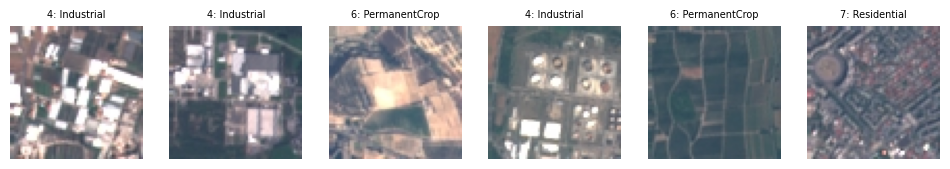

In [11]:
# ---------- ПРОВЕРКА, что загрузка корректна ----------
print("train labels: min", y_train.min(), "max", y_train.max(), "| уникальных:", len(np.unique(y_train)), "из", NUM_CLASSES)
print("test  labels: min", y_test.min(),  "max", y_test.max(),  "| уникальных:", len(np.unique(y_test)))
print("pixel range:", X_train.min(), "-", X_train.max())
print("train/val overlap (должно быть 0):", len(set(train_idx) & set(val_idx)))

fig, ax = plt.subplots(1, 6, figsize=(12, 2.6))
for a, i in zip(ax, range(6)):
    a.imshow(X_train[i]); a.set_title(f"{y_train[i]}: {CLASS_NAMES[y_train[i]][:16]}", fontsize=7); a.axis("off")
plt.show()

### 🔍 Разбор
Быстрая проверка перед тем как идти дальше (всегда делай её на новом датасете):
- Метки от 0 до K−1, уникальных близко к `NUM_CLASSES` — иначе потерян класс или неверные метки.
- Пиксели 0…255, формат `uint8`.
- Пересечение train/val = 0.
- На картинках видны настоящие объекты с правильными подписями; цвета естественные (если красное стало синим — перепутаны BGR/RGB).

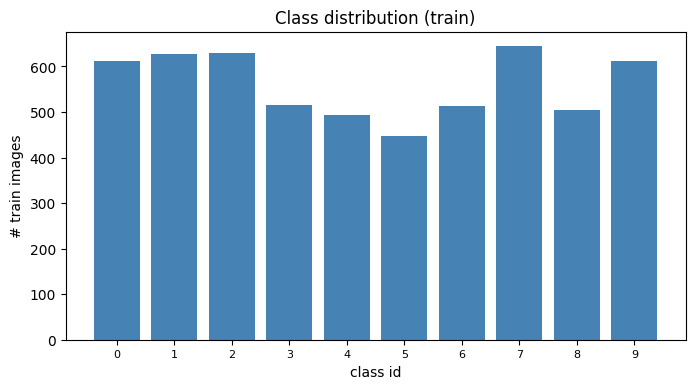

most frequent : class 7 (Residential) = 644 images
least frequent: class 5 (Pasture) = 447 images
imbalance ratio max/min = 1.4x


In [12]:
counts = np.bincount(y_train, minlength=NUM_CLASSES)     # сколько картинок каждого класса в train

plt.figure(figsize=(max(8, NUM_CLASSES * 0.3), 4))
plt.bar(np.arange(NUM_CLASSES), counts, color="steelblue")
plt.xticks(np.arange(NUM_CLASSES), fontsize=8)
plt.xlabel("class id"); plt.ylabel("# train images")
plt.title("Class distribution (train)")
plt.show()

print(f"most frequent : class {counts.argmax()} ({CLASS_NAMES[counts.argmax()]}) = {counts.max()} images")
print(f"least frequent: class {counts.argmin()} ({CLASS_NAMES[counts.argmin()]}) = {counts.min()} images")
print(f"imbalance ratio max/min = {counts.max()/max(counts.min(),1):.1f}x")

### 🔍 Разбор
- **`np.bincount(y_train, minlength=K)`** — считает, сколько раз встречается каждое число 0…K−1 в массиве меток.
- **`plt.bar`** — столбики: по x — номер класса, по y — число картинок.
- **Как комментировать:** посмотри на отношение max/min. Если порядка 5–10× и больше — датасет **несбалансирован** (для GTSRB ≈ 10×): модель оптимизирует среднюю ошибку, редкие классы почти не влияют на неё → учит их хуже (см. Part D). Если ≈ 1× (FashionMNIST, CIFAR-10 — идеально ровные) — дисбаланса нет, и эксперимент Part D про дисбаланс покажет ~нулевой эффект; тогда честно так и напиши и/или возьми другой эксперимент (шаблон в конце Part D).

In [14]:
# Статистика нормализации считаем ТОЛЬКО по train (нельзя подглядывать в val/test)
x = X_train.astype(np.float32) / 255.0
mean = x.mean(axis=(0, 1, 2))     # среднее по каналам R, G, B
std  = x.std(axis=(0, 1, 2))
del x

if PRETRAINED and MODEL_KIND != "own":                 # предобученные модели ждут статистику ImageNet
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
print("mean:", mean.round(4), "| std:", std.round(4))

mean_t = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
std_t  = torch.tensor(std,  dtype=torch.float32).view(3, 1, 1)

def denorm(t):
    # тензор [3,H,W] после Normalize -> картинка (H,W,3) в [0,1] для показа
    return (t * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

mean: [0.485 0.456 0.406] | std: [0.229 0.224 0.225]


### 🔍 Разбор
- **Нормализация** = `(пиксель − mean) / std` по каждому каналу: сеть обучается быстрее и стабильнее, когда входы центрированы около 0 и масштаб ~1.
- `astype(np.float32) / 255.0` — из 0–255 в 0–1 (в такой шкале `ToTensor` отдаёт картинки). `.mean(axis=(0,1,2))` — усредняем по картинкам, высоте и ширине → 3 числа (по каналу).
- **Только по train**, иначе «утечка» информации из теста. Для val/test используем те же mean/std.
- **Предобученные модели** (`PRETRAINED=True`) обучались на ImageNet с фиксированной статистикой `[0.485, 0.456, 0.406]` / `[0.229, 0.224, 0.225]` — подаём данные в той же шкале.
- **`denorm`** — обратная операция, чтобы показывать нормализованные тензоры как картинки (`permute(1,2,0)`: `[C,H,W]` → `[H,W,C]` для matplotlib).

In [15]:
class AddGaussianNoise:
    # Добавляет гауссов шум к тензору в шкале [0,1]. Нужен только для "robust" режима (Part E).
    def __init__(self, std_max=0.1, p=0.3):
        self.std_max, self.p = std_max, p
    def __call__(self, t):
        if random.random() < self.p:
            t = (t + torch.randn_like(t) * random.uniform(0, self.std_max)).clamp(0, 1)
        return t

def make_train_tf(robust=False):
    ops = []
    if USE_HFLIP:                                   # 🔧 управляется в CONFIG: True только если зеркало не меняет класс
        ops.append(transforms.RandomHorizontalFlip())
    ops.append(transforms.RandomAffine(degrees=AUG_ROTATION, translate=(AUG_TRANSLATE, AUG_TRANSLATE), scale=AUG_SCALE))
    if robust:   # усиленная версия для Part E (темнота, размытие, шум)
        ops += [transforms.ColorJitter(brightness=(0.2, 1.3), contrast=(0.5, 1.3)),
                transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3)]
    else:        # обычная версия
        ops.append(transforms.ColorJitter(brightness=AUG_BRIGHTNESS, contrast=AUG_CONTRAST))
    ops.append(transforms.ToTensor())
    if robust:
        ops.append(AddGaussianNoise(0.1, 0.3))
    ops.append(transforms.Normalize(mean.tolist(), std.tolist()))
    return transforms.Compose(ops)

eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean.tolist(), std.tolist())])

class NumpyDataset(Dataset):
    # Dataset поверх numpy-массивов. Применяет transform "на лету" при каждом обращении.
    def __init__(self, X, y, transform=None):
        self.X, self.y, self.transform = X, y, transform
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        img = Image.fromarray(self.X[i])
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.y[i])

def make_loader(X, y, tf, shuffle=False, sampler=None):
    ds = NumpyDataset(X, y, tf)
    return DataLoader(ds, batch_size=BATCH, shuffle=(shuffle and sampler is None), sampler=sampler,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

train_loader = make_loader(X_train, y_train, make_train_tf(False), shuffle=True)
val_loader   = make_loader(X_val,   y_val,   eval_tf)
print("batches per epoch (train):", len(train_loader), "| USE_HFLIP =", USE_HFLIP)

batches per epoch (train): 44 | USE_HFLIP = True


### 🔍 Разбор
**Главный вопрос: безопасен ли flip для МОИХ классов?** Правило: аугментация должна **сохранять метку**. Задай себе вопрос: «если зеркально отразить картинку, станет ли это другим классом или нереалистичной картинкой?»

| Данные | `USE_HFLIP` | Почему |
|---|---|---|
| Дорожные знаки (GTSRB) | ❌ False | «поворот налево» ↔ «направо», «держись правее» ↔ «левее» — flip меняет класс при той же метке; цифры и надписи становятся зеркальными |
| Цифры, буквы, текст | ❌ False | зеркальные символы не существуют / 2 ↔ 5 и т.п. |
| Одежда (FashionMNIST), животные, цветы, машины сбоку, лица | ✅ True | зеркало не меняет класс, реалистично |
| Спутниковые снимки, микроскопия | ✅ True (и вертикальный flip, повороты на 90°) | у снимка «сверху» нет выделенных сторон |
| Медицина (рентген) | ⚠️ осторожно | сторона тела (сердце слева) может быть значимой |

**Остальные аугментации и их безопасность:**
- `RandomAffine(degrees, translate, scale)` — небольшие поворот/сдвиг/масштаб имитируют разный ракурс и расстояние; малые значения не меняют смысл. Большие повороты опасны там, где ориентация несёт смысл (6 ↔ 9, стрелки).
- `ColorJitter(brightness, contrast)` — яркость/контраст (день/ночь). **`hue` (оттенок) мы НЕ трогаем**: если цвет несёт смысл (красный знак = запрет, цвет цветка, спелость плода), сдвиг оттенка исказил бы класс.

**`AddGaussianNoise`** — класс-«вызываемый» объект (`__call__`), чтобы вписаться в `transforms.Compose`; с вероятностью `p` добавляет шум случайной силы, `.clamp(0,1)` не даёт выйти из диапазона. Только для robust-режима (Part E).

**`make_train_tf(robust)`** собирает цепочку: (flip) → аффин → цвет → `ToTensor` (PIL → тензор `[3,H,W]` в 0–1) → (шум) → `Normalize`. Порядок важен: шум работает с тензором, поэтому после `ToTensor`.

**`eval_tf`** — для val/test **без аугментаций**: только `ToTensor` + `Normalize`. Аугментации — только для обучения!

**`NumpyDataset`** — наш `Dataset` (три метода: `__init__`, `__len__`, `__getitem__`). DataLoader вызывает `__getitem__(i)` и применяет transform «на лету» → каждую эпоху одна картинка выглядит чуть по-разному.

**`make_loader`** — оборачивает в `DataLoader`: режет на батчи, перемешивает (`shuffle=True` для train), грузит параллельно (`num_workers`). Если задан `sampler`, `shuffle` должен быть `False` (взаимоисключающие). `pin_memory` ускоряет копирование на GPU.

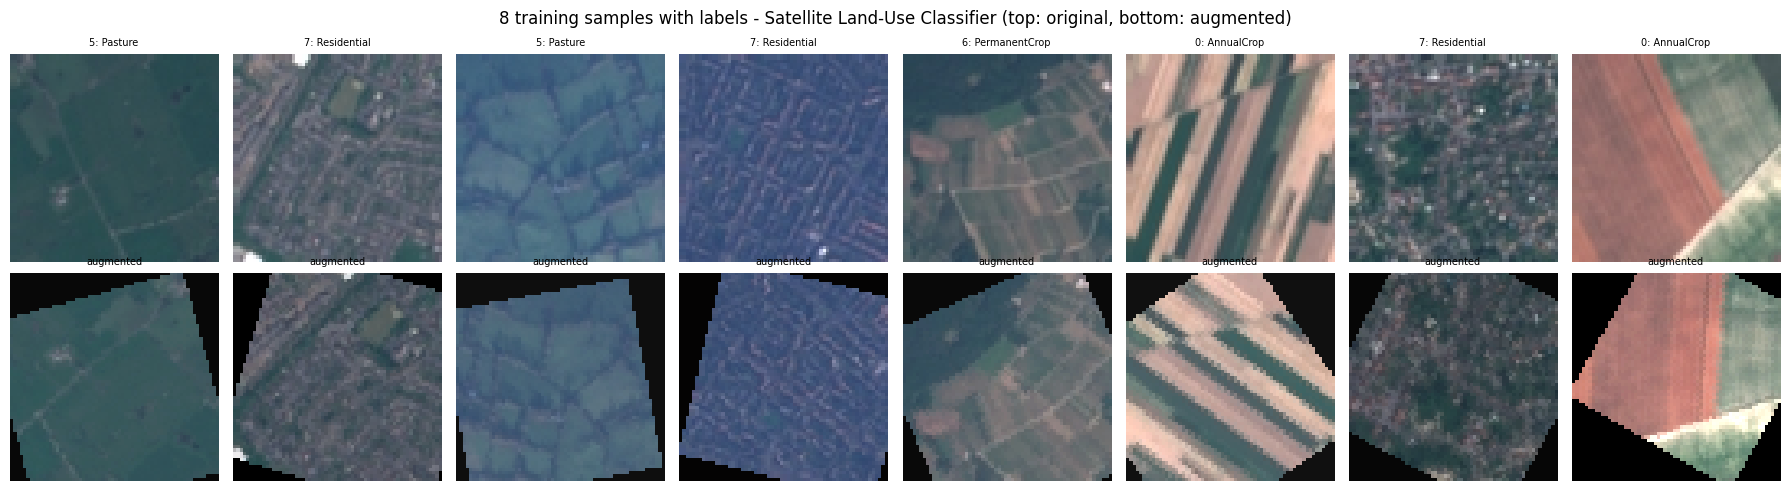

In [16]:
# 8 примеров с метками: верхний ряд = исходные, нижний ряд = те же после аугментации
tf_demo = make_train_tf(False)
idx = np.random.RandomState(1).choice(len(X_train), 8, replace=False)

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
for j, i in enumerate(idx):
    axes[0, j].imshow(X_train[i])
    axes[0, j].set_title(f"{y_train[i]}: {CLASS_NAMES[y_train[i]][:18]}", fontsize=7)
    axes[0, j].axis("off")
    aug = tf_demo(Image.fromarray(X_train[i]))
    axes[1, j].imshow(denorm(aug)); axes[1, j].set_title("augmented", fontsize=7); axes[1, j].axis("off")
plt.suptitle(f"8 training samples with labels - {TASK_NAME} (top: original, bottom: augmented)")
plt.tight_layout(); plt.show()

### 🔍 Разбор
- `np.random.RandomState(1).choice(N, 8, replace=False)` — 8 случайных *разных* индексов, фиксированный seed → те же картинки при перезапуске.
- Двойной цикл: верхний ряд — исходные 8 картинок с **метками в заголовке** («номер: название класса» — требование задания); нижний — те же после аугментаций + `denorm`.
- Что проверять глазами: аугментированные картинки остаются узнаваемыми и **не поменяли класс**. Если после аугментации класс уже не узнать (слишком большой поворот/сдвиг) — уменьши значения в CONFIG.

# Part B — Model [20 pts]

**Нужно:** обучить свою CNN (≥ 3 conv-блока) *или* дообучить MobileNetV2/ResNet-18; обосновать выбор для лёгкого устройства; указать число параметров.

Выбор модели — в CONFIG: `MODEL_KIND = "own" | "resnet18" | "mobilenet_v2"`, `PRETRAINED = True/False`.

In [17]:
def conv_block(c_in, c_out):
    # Блок: [Conv3x3 -> BN -> ReLU] x2 -> MaxPool2x2 ; размер карты уменьшается вдвое
    return nn.Sequential(
        nn.Conv2d(c_in,  c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),     # IMG   -> IMG/2
            conv_block(32, 64),    # IMG/2 -> IMG/4
            conv_block(64, 128),   # IMG/4 -> IMG/8
        )
        self.pool = nn.AdaptiveAvgPool2d(1)   # (128, h, w) -> (128, 1, 1), работает при любом размере картинки
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(128, num_classes))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def build_model(kind=MODEL_KIND, pretrained=PRETRAINED):
    if kind == "own":
        return SimpleCNN()
    if kind == "resnet18":
        m = models.resnet18(weights="DEFAULT" if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)                      # меняем последний слой под наши классы
        return m
    if kind == "mobilenet_v2":
        m = models.mobilenet_v2(weights="DEFAULT" if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, NUM_CLASSES)
        return m
    raise ValueError(f"Неизвестный MODEL_KIND: {kind}")

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

net = build_model()
print(f"MODEL_KIND = {MODEL_KIND} | PRETRAINED = {PRETRAINED}")
print(f"{type(net).__name__}: trainable parameters = {count_params(net):,}")

# --- как меняется форма тензора внутри своей сети ---
if MODEL_KIND == "own":
    h = torch.zeros(1, 3, IMG, IMG)
    print("\ninput:", tuple(h.shape))
    for k, blk in enumerate(net.features):
        h = blk(h); print(f"after conv block {k+1}:", tuple(h.shape))
    h = net.pool(h); print("after global avg pool:", tuple(h.shape))
    print("logits:", tuple(net(torch.zeros(1, 3, IMG, IMG)).shape))

# --- для сравнения: параметры стандартных лёгких моделей (с головой под наши классы) ---
for name in ["own", "mobilenet_v2", "resnet18"]:
    print(f"{name:13s}: {count_params(build_model(name, False)):>12,} params")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 184MB/s]


MODEL_KIND = resnet18 | PRETRAINED = True
ResNet: trainable parameters = 11,181,642
own          :      288,746 params
mobilenet_v2 :    2,236,682 params
resnet18     :   11,181,642 params


### 🔍 Разбор
**`conv_block`** — один «блок»:
- `Conv2d(c_in, c_out, 3, padding=1)` — свёртка 3×3; `padding=1` (рамка из нулей) сохраняет размер карты; `c_in` — каналов на входе, `c_out` — число фильтров.
- `bias=False` — смещение не нужно, т.к. следом `BatchNorm` со своим сдвигом.
- `BatchNorm2d` → `ReLU` — стабилизация + нелинейность. Две свёртки подряд = больший «обзор» (рецептивное поле) при малом числе параметров.
- `MaxPool2d(2)` — размер вдвое меньше.

**`SimpleCNN`** — три блока с каналами **3→32→64→128** (это и есть «≥ 3 conv-блока»): глубже → больше фильтров, но карта меньше. `AdaptiveAvgPool2d(1)` (GAP) → 128 чисел → `Dropout` → `Linear(128, K)`. Из-за GAP сеть работает при любом `IMG` и имеет мало параметров. `Dropout` сам выключается в `eval()`.

**`build_model`** — фабрика: по названию возвращает нужную модель. Для `resnet18`/`mobilenet_v2` мы **заменяем последний слой** на `Linear(..., NUM_CLASSES)` (у ImageNet-модели он на 1000 классов). `weights="DEFAULT"` скачивает предобученные веса (**fine-tuning** — дообучение на наших данных), `None` — случайная инициализация. Для fine-tuning обычно ставят меньший `LR` (≈3e-4) и больший `IMG` (64–96).

**`count_params`** — сумма `numel()` обучаемых тензоров. Это и есть **«number of parameters»** для отчёта.

**Цикл «форма тензора»** — проверка, что ты понимаешь, что внутри (`[1,32,IMG/2,…]`, … → GAP → логиты `[1,K]`).

**Обоснование выбора для in-car / лёгкого устройства (для отчёта и защиты):**
1. **Размер и память.** Своя сеть ≈ 0,3 М параметров (≈ 1,2 МБ) против ≈ 2–3,5 М у MobileNetV2 и ≈ 11 М у ResNet-18 (точные числа напечатаны выше) — в 10–40 раз меньше. Встроенное устройство ограничено по памяти, питанию, нагреву.
2. **Скорость (latency).** Малый вход (48×48) и ~90 млн операций на картинку → мгновенный отклик даже на слабом железе.
3. **Задача простая** — чёткие объекты, малое число классов: огромная модель избыточна.
4. **Предобученные модели заточены под 224×224.** На 48×48 их ранние слои сожмут карту до ~2×2 — мощность тратится впустую.
5. **GAP вместо полносвязных слоёв** — главная причина малого числа параметров и меньше переобучения.
- *Честный минус:* fine-tuning предобученной модели часто даёт чуть лучшую точность и сходится за меньше эпох, особенно если данных мало или задача сложная (много классов, текстуры) — ценой размера. Если на экзамене задача *не про лёгкое устройство*, предобученная модель — вполне разумный выбор; аргументируй по условию.

In [18]:
def run_epoch(model, loader, criterion, optimizer=None):
    # Один проход по loader. Если optimizer задан -> обучение, иначе -> только оценка.
    training = optimizer is not None
    model.train(training)                 # train(): Dropout включён, BatchNorm обновляется; eval(): выключены
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):    # при оценке градиенты не считаем (быстрее, меньше памяти)
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)                   # логиты [B, K]
            loss = criterion(out, yb)
            if training:
                optimizer.zero_grad()         # обнуляем старые градиенты
                loss.backward()               # считаем новые (обратное распространение)
                optimizer.step()              # шаг оптимизатора: меняем веса
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, criterion, epochs=EPOCHS, lr=LR, name="model"):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    val_criterion = nn.CrossEntropyLoss()     # для val всегда обычный CE, чтобы кривые были сравнимы
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = -1.0, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, val_criterion)
        scheduler.step()
        for k, v in zip(hist.keys(), (tl, vl, ta, va)):
            hist[k].append(v)
        if va > best_acc:
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {ep:2d}/{epochs} | train loss {tl:.3f} acc {ta:.3f} | "
              f"val loss {vl:.3f} acc {va:.3f} | {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)         # возвращаем веса лучшей по val эпохи
    print(f"[{name}] best val acc = {best_acc:.4f}")
    return model, hist

### 🔍 Разбор
**`run_epoch`** — сердце обучения (одна функция и для обучения, и для оценки):
- `model.train(True/False)` — режим. В train включён Dropout и BatchNorm обновляет статистику; в eval всё «заморожено». Забыть `model.eval()` при тесте — классическая ошибка.
- `torch.set_grad_enabled(training)` — при оценке граф вычислений не строим (экономия).
- В цикле по батчам: данные на `device`; `out = model(xb)` — **прямой проход**; `loss = criterion(out, yb)` — ошибка.
- Три ключевые строки обучения: `zero_grad()` (стереть старые градиенты, иначе накапливаются) → `loss.backward()` (посчитать градиенты) → `optimizer.step()` (обновить веса).
- `out.argmax(1)` — класс с максимальным логитом; считаем верные; `.item()` достаёт число из тензора. Loss умножаем на размер батча для корректного среднего по эпохе.

**`fit`** — цикл по эпохам:
- **Adam** (`lr=LR`) — адаптивный оптимизатор; `weight_decay=1e-4` — лёгкая L2-регуляризация.
- **`CosineAnnealingLR`** — скорость обучения плавно падает по косинусу: сначала большие шаги, к концу — доводка; `scheduler.step()` раз в эпоху.
- `hist` — история для графиков.
- **Лучшая эпоха:** копия весов (`deepcopy(state_dict)`) при лучшей val-accuracy; в конце загружаем её — защита от неудачной последней эпохи.
- `criterion` передаётся снаружи → в Part D подставим другой loss.

In [19]:
models_d, hists_d = {}, {}      # здесь копим обученные модели и их кривые по названию стратегии

set_seed()
model_plain = build_model()
model_plain, hist_plain = fit(model_plain, train_loader, val_loader, nn.CrossEntropyLoss(), name="plain")
models_d["plain"], hists_d["plain"] = model_plain, hist_plain

[plain] epoch  1/15 | train loss 0.708 acc 0.764 | val loss 0.448 acc 0.862 | 7s
[plain] epoch  2/15 | train loss 0.401 acc 0.870 | val loss 0.211 acc 0.931 | 6s
[plain] epoch  3/15 | train loss 0.287 acc 0.906 | val loss 0.380 acc 0.882 | 5s
[plain] epoch  4/15 | train loss 0.262 acc 0.912 | val loss 0.341 acc 0.892 | 5s
[plain] epoch  5/15 | train loss 0.248 acc 0.915 | val loss 0.162 acc 0.940 | 6s
[plain] epoch  6/15 | train loss 0.234 acc 0.922 | val loss 0.180 acc 0.938 | 5s
[plain] epoch  7/15 | train loss 0.206 acc 0.931 | val loss 0.195 acc 0.931 | 5s
[plain] epoch  8/15 | train loss 0.188 acc 0.937 | val loss 0.168 acc 0.939 | 5s
[plain] epoch  9/15 | train loss 0.145 acc 0.951 | val loss 0.157 acc 0.955 | 5s
[plain] epoch 10/15 | train loss 0.146 acc 0.946 | val loss 0.119 acc 0.958 | 6s
[plain] epoch 11/15 | train loss 0.112 acc 0.963 | val loss 0.107 acc 0.965 | 5s
[plain] epoch 12/15 | train loss 0.109 acc 0.963 | val loss 0.101 acc 0.963 | 4s
[plain] epoch 13/15 | train 

### 🔍 Разбор
- `set_seed()` перед созданием модели → одинаковая начальная инициализация весов у всех сравниваемых моделей.
- **`nn.CrossEntropyLoss()`** — стандартный loss классификации: внутри softmax (логиты → вероятности) и `−log(вероятность правильного класса)`. Чем увереннее и правильнее, тем меньше.
- Это **baseline («plain training»)** — обычное обучение; с ним сравниваем в Part D.
- В выводе: train acc растёт, val acc выходит на плато; train ≫ val → переобучение. Если не хватает времени — уменьши `EPOCHS` в CONFIG и перезапусти.

# Part C — Evaluation [20 pts]

**Нужно:** кривые обучения, test accuracy и macro-F1, confusion matrix для 10 самых частых классов, 3 худших класса.

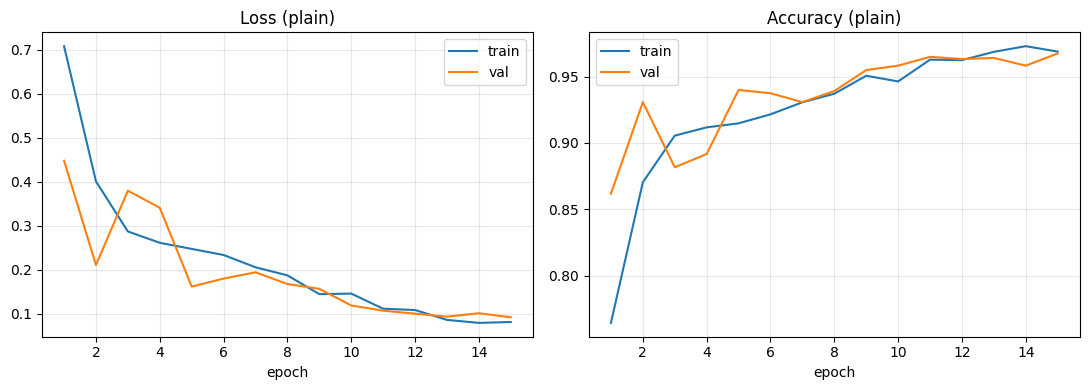

TEST accuracy = 0.9602  |  TEST macro-F1 = 0.9591


In [20]:
@torch.no_grad()
def predict(model, X, batch=512):
    # Предсказанные классы для массива картинок X (N,H,W,3 uint8)
    model.eval()
    loader = DataLoader(NumpyDataset(X, np.zeros(len(X), dtype=np.int64), eval_tf),
                        batch_size=batch, shuffle=False, num_workers=NUM_WORKERS)
    preds = []
    for xb, _ in loader:
        preds.append(model(xb.to(device)).argmax(1).cpu().numpy())
    return np.concatenate(preds)

def evaluate(model, X, y):
    p = predict(model, X)
    return accuracy_score(y, p), f1_score(y, p, average="macro", zero_division=0), p

def plot_history(hist, title=""):
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="val")
    ax[0].set_title(f"Loss {title}"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="val")
    ax[1].set_title(f"Accuracy {title}"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

plot_history(hist_plain, "(plain)")

acc, mf1, preds = evaluate(model_plain, X_test, y_test)
print(f"TEST accuracy = {acc:.4f}  |  TEST macro-F1 = {mf1:.4f}")

### 🔍 Разбор
- **`@torch.no_grad()`** — внутри градиенты не нужны.
- **`predict`**: `model.eval()` обязательно! Прогоняем массив через `eval_tf` (без аугментаций) батчами по 512, `argmax(1)` берёт класс, `.cpu().numpy()` переносит с GPU в numpy, `np.concatenate` склеивает батчи. Метки подставляем нулевые — для предсказания не нужны.
- **`evaluate`** возвращает accuracy, **macro-F1** (`average="macro"`: F1 каждого класса → простое среднее; `zero_division=0`: если у класса нет предсказаний, F1=0 вместо ошибки) и сами предсказания.
- **`plot_history`**: loss и accuracy по эпохам. Как читать: оба loss падают и сближаются → норма; train loss падает, а val loss растёт/стоит → переобучение; оба высокие → недообучение.
- Числа **на тесте** идут в отчёт.

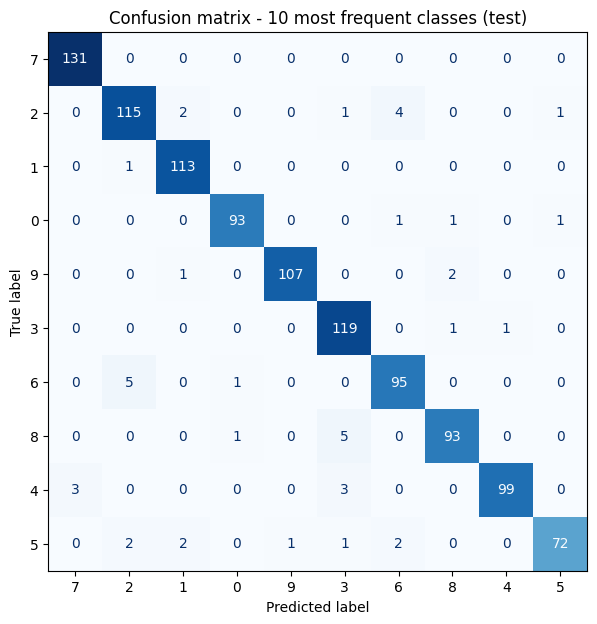

 7 = Residential
 2 = HerbaceousVegetation
 1 = Forest
 0 = AnnualCrop
 9 = SeaLake
 3 = Highway
 6 = PermanentCrop
 8 = River
 4 = Industrial
 5 = Pasture

Test images of these classes: 1080, of them predicted as some OTHER class (not shown): 0


In [21]:
# ---- Confusion matrix для TOP_K самых частых классов ----
TOP_K = min(10, NUM_CLASSES)
top10 = np.argsort(-counts)[:TOP_K]                   # классы с наибольшим числом train-картинок
cm = confusion_matrix(y_test, preds, labels=top10)    # строки/столбцы только для этих классов


fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=top10).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix - {TOP_K} most frequent classes (test)")
plt.show()
for c in top10:
    print(f"{c:2d} = {CLASS_NAMES[c]}")

mask = np.isin(y_test, top10)
outside = (~np.isin(preds[mask], top10)).sum()
print(f"\nTest images of these classes: {mask.sum()}, of them predicted as some OTHER class (not shown): {outside}")

### 🔍 Разбор
- **`np.argsort(-counts)[:10]`** — `argsort` сортирует *индексы* по возрастанию значений; минус разворачивает порядок → сначала индексы самых частых классов; `[:10]` — первые десять. «Частые» считаем по train.
- **`confusion_matrix(y_test, preds, labels=top10)`** — матрица: строка = **истинный** класс, столбец = **предсказанный**. Клетка (i, j) — сколько картинок класса i предсказано как j. Диагональ = `correct_c`; идеал — только диагональ.
- Матрица учитывает только пары, где *и истина, и предсказание* из выбранных классов; последние строки печатают, сколько картинок этих классов ушло в чужие классы (вне матрицы).
- **Как комментировать:** тёмная диагональ = высокая точность; светлые клетки вне диагонали = путаница между конкретными классами (обычно похожие объекты).

In [22]:
# ---- 3 худших класса по F1 ----
f1_cls  = f1_score(y_test, preds, average=None, labels=np.arange(NUM_CLASSES), zero_division=0)
rec_cls = np.array([(preds[y_test == c] == c).mean() if (y_test == c).any() else np.nan for c in range(NUM_CLASSES)])
support = np.bincount(y_test, minlength=NUM_CLASSES)

df_cls = pd.DataFrame({"class": np.arange(NUM_CLASSES), "name": CLASS_NAMES, "f1": f1_cls,
                       "recall": rec_cls, "test_support": support, "train_count": counts})
worst3 = df_cls.sort_values("f1").head(3)
display(worst3.round(3))

# с чем чаще всего путают худшие классы
for c in worst3["class"]:
    wrong = (y_test == c) & (preds != c)
    if wrong.sum() == 0:
        print(f"class {c}: no missed images (low F1 comes from other classes being predicted as {c})")
        continue
    top_wrong = np.bincount(preds[wrong], minlength=NUM_CLASSES).argmax()
    print(f"class {c} ({CLASS_NAMES[c]}) is most often confused with class {top_wrong} ({CLASS_NAMES[top_wrong]})")

,class,name,f1,recall,test_support,train_count
2,2,HerbaceousVegetation,0.935,0.935,123,630
5,5,Pasture,0.935,0.900,80,447
6,6,PermanentCrop,0.936,0.941,101,513


class 2 (HerbaceousVegetation) is most often confused with class 6 (PermanentCrop)
class 5 (Pasture) is most often confused with class 1 (Forest)
class 6 (PermanentCrop) is most often confused with class 2 (HerbaceousVegetation)


### 🔍 Разбор
- **`f1_score(..., average=None, labels=range(K))`** — не усредняет, а возвращает **F1 каждого класса**. Берём три наименьших.
- **recall по классу:** `preds[y_test == c]` — предсказания для картинок настоящего класса c; `(… == c).mean()` — доля верных (= `correct_c / true_c`).
- **`test_support`** — сколько картинок класса в тесте (мало → F1 менее надёжен); **`train_count`** — сразу видно, редкий ли класс.
- **«С чем путают»:** для каждого худшего класса берём ошибочные предсказания и ищем самое частое неверное (`bincount(...).argmax()`). Если пропусков нет (`wrong.sum()==0`), низкий F1 объясняется *ложными срабатываниями* (другие классы ошибочно названы этим — низкая precision).
- В отчёте: назови 3 класса, их F1 и *почему* (мало примеров? похожи на другой класс? мелкие детали при малом `IMG`?).

# Part D — Experiment: class imbalance [15 pts]

**Нужно:** сравнить стратегии борьбы с дисбалансом: *plain* (уже обучена), *class-weighted loss*, *oversampling*; показать изменение macro-F1 и accuracy.

Если в твоём варианте экзамена эксперимент **другой** (аугментация vs без, своя CNN vs предобученная, другой оптимизатор…) — используй шаблон в конце этого раздела.

In [ ]:
# --- Стратегия 2: взвешенная функция потерь ---
# вес класса = N / (K * n_c): редкие классы -> большой вес, частые -> маленький (среднее ~1)
class_w = counts.sum() / (NUM_CLASSES * np.maximum(counts, 1))
class_w_t = torch.tensor(class_w, dtype=torch.float32, device=device)
print("weights: min %.2f (class %d) | max %.2f (class %d)" % (class_w.min(), class_w.argmin(), class_w.max(), class_w.argmax()))

# --- Стратегия 3: oversampling через WeightedRandomSampler ---
sample_w = 1.0 / np.maximum(counts, 1)[y_train]          # вес каждой КАРТИНКИ = 1 / размер её класса
sampler = WeightedRandomSampler(torch.tensor(sample_w, dtype=torch.double),
                                num_samples=len(y_train), replacement=True)

def make_strategy(strategy, robust=False):
    # Возвращает (train_loader, criterion) для стратегии: "plain" | "weighted" | "oversample"
    tf = make_train_tf(robust)
    if strategy == "weighted":
        return make_loader(X_train, y_train, tf, shuffle=True), nn.CrossEntropyLoss(weight=class_w_t)
    if strategy == "oversample":
        return make_loader(X_train, y_train, tf, sampler=sampler), nn.CrossEntropyLoss()
    return make_loader(X_train, y_train, tf, shuffle=True), nn.CrossEntropyLoss()

for s in ["weighted", "oversample"]:
    set_seed()
    m = build_model()
    loader, crit = make_strategy(s)
    models_d[s], hists_d[s] = fit(m, loader, val_loader, crit, name=s)

### 🔍 Разбор
**Идея обеих стратегий:** заставить модель «ценить» ошибки на редких классах так же, как на частых.

**Class-weighted loss:**
- `class_w = N / (K · n_c)` (N — всего картинок, K — число классов, n_c — картинок класса c). Редкий класс → *большой* вес, частый → *малый*; в среднем ≈ 1. `np.maximum(counts, 1)` — защита от деления на 0.
- `nn.CrossEntropyLoss(weight=class_w_t)` — ошибка на картинке умножается на вес её класса → градиенты от редких классов «громче». Данные не меняются, меняется только штраф.

**Oversampling:**
- Вес каждой картинки = `1 / (размер её класса)`; `[y_train]` — «раздать» вес класса каждой картинке.
- `WeightedRandomSampler(weights, num_samples, replacement=True)` тянет картинки пропорционально весу **с возвращением** → редкие попадают в эпоху много раз (каждый раз с новой аугментацией), частые реже. Батчи становятся ~сбалансированными; loss обычный CE.
- Минус: редкие картинки повторяются → риск запомнить их (смягчает аугментация).

**`make_strategy`** — фабрика «загрузчик + loss» по названию стратегии; `robust` нужен в Part E.

**Цикл** обучает по новой модели на каждую стратегию с одним seed → сравнение честное (отличается только стратегия).

,accuracy,macro_f1,mean_F1_of_5_rarest
strategy,,,
plain,0.9602,0.9591,0.9476
no_aug,0.9583,0.9571,0.9469



Change vs plain (percentage points):


,accuracy,macro_f1,mean_F1_of_5_rarest
strategy,,,
plain,0.00,0.0,0.00
no_aug,-0.19,-0.2,-0.07


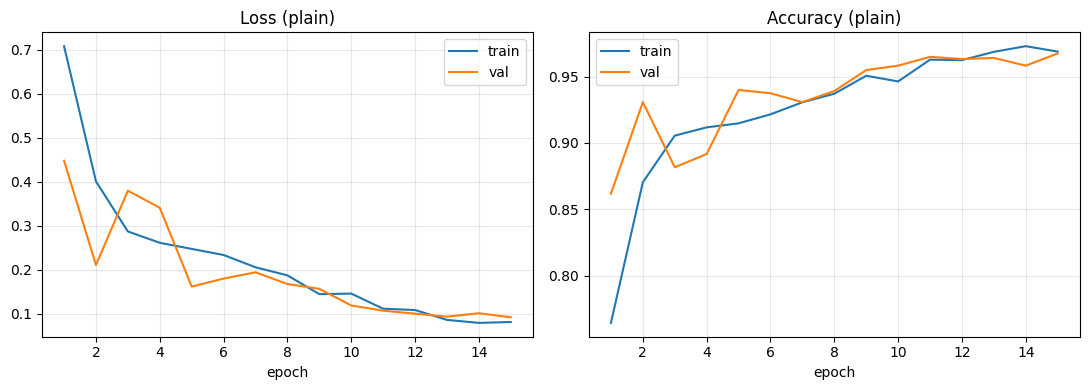

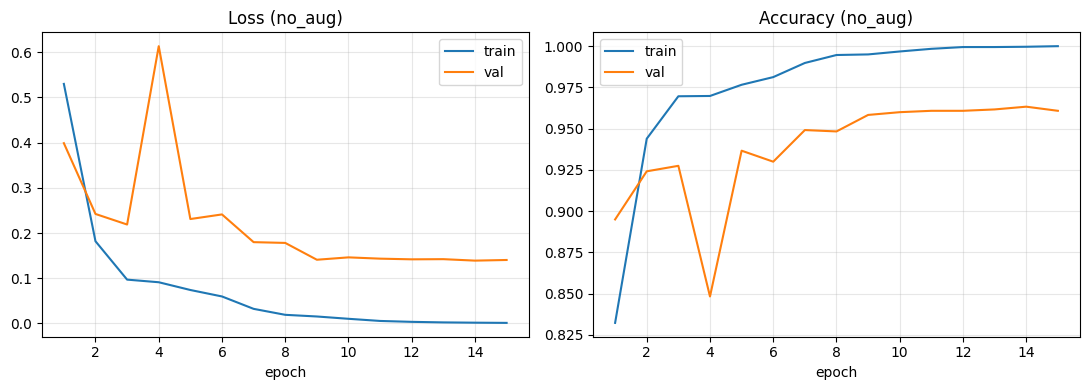

>>> FINAL model: plain


In [25]:
rare5 = np.argsort(counts)[:min(5, NUM_CLASSES)]       # 5 самых редких классов

rows = []
for s, m in models_d.items():
    a, f, p = evaluate(m, X_test, y_test)
    f1c = f1_score(y_test, p, average=None, labels=np.arange(NUM_CLASSES), zero_division=0)
    rows.append({"strategy": s, "accuracy": a, "macro_f1": f, "mean_F1_of_5_rarest": f1c[rare5].mean()})
results = pd.DataFrame(rows).set_index("strategy")
display(results.round(4))

base = results.loc["plain"]
print("\nChange vs plain (percentage points):")
display(((results - base) * 100).round(2))

for s in models_d:
    plot_history(hists_d[s], f"({s})")

final_name = results["macro_f1"].idxmax()          # финальная модель = лучшая по macro-F1
final_model = models_d[final_name]
print(">>> FINAL model:", final_name)

### 🔍 Разбор
- Для **каждой** модели на тесте считаем accuracy, macro-F1 и **средний F1 на 5 самых редких классах** — именно там должен проявиться эффект борьбы с дисбалансом.
- Таблица `results` + вторая — «изменение относительно plain в процентных пунктах» (`(results − base) × 100`) → готовый материал для отчёта.
- **`results["macro_f1"].idxmax()`** — название лучшей стратегии → она становится **финальной моделью** для Part E (цель — хорошо знать *все* классы).

**Как интерпретировать (для анализа и защиты):**
- Типичный результат: weighted/oversampling слегка поднимают macro-F1 и F1 на редких классах, а accuracy меняется мало (иногда чуть падает). Это нормально: **accuracy в основном отражает частые классы, macro-F1 — все одинаково**.
- ⚠️ Оговорка: каждая модель обучена **с одним seed**. Разница в 0,1–0,5 п.п. может быть просто шумом. Если разница крошечная, так и напиши («значимого улучшения не наблюдается»), а не выдумывай победителя.
- При умеренном дисбалансе (≈ 10×) и визуально различимых классах эффект часто небольшой — это валидный вывод. Если датасет **сбалансирован**, ожидай ≈ 0 эффекта.

In [24]:
# ============ ШАБЛОН: свой эксперимент (если в задании он другой) ============
# 🔧 Раскомментируй нужное, запусти ПЕРЕД ячейкой с таблицей results выше (или перезапусти её после).
# Любая модель, добавленная в словарь models_d, автоматически попадёт в таблицу results.

# (1) Своя CNN vs предобученный ResNet-18:
# set_seed()
# m = build_model("resnet18", pretrained=True)
# loader, crit = make_strategy("plain")
# models_d["resnet18_pretrained"], hists_d["resnet18_pretrained"] = fit(m, loader, val_loader, crit, lr=3e-4, name="resnet18_pt")

# (2) С аугментациями vs без аугментаций:
set_seed()
m = build_model()
loader_noaug = make_loader(X_train, y_train, eval_tf, shuffle=True)   # eval_tf = без аугментаций
models_d["no_aug"], hists_d["no_aug"] = fit(m, loader_noaug, val_loader, nn.CrossEntropyLoss(), name="no_aug")

# (3) Другой размер входа / другой LR / другой оптимизатор: поменяй параметр в CONFIG и перезапусти обучение;
#     или передай lr=... в fit(...). Для другого оптимизатора поменяй строку optimizer = ... внутри fit.

[no_aug] epoch  1/15 | train loss 0.530 acc 0.832 | val loss 0.399 acc 0.895 | 3s
[no_aug] epoch  2/15 | train loss 0.182 acc 0.944 | val loss 0.242 acc 0.924 | 3s
[no_aug] epoch  3/15 | train loss 0.097 acc 0.970 | val loss 0.219 acc 0.927 | 3s
[no_aug] epoch  4/15 | train loss 0.091 acc 0.970 | val loss 0.614 acc 0.848 | 3s
[no_aug] epoch  5/15 | train loss 0.074 acc 0.977 | val loss 0.231 acc 0.937 | 3s
[no_aug] epoch  6/15 | train loss 0.060 acc 0.981 | val loss 0.241 acc 0.930 | 3s
[no_aug] epoch  7/15 | train loss 0.032 acc 0.990 | val loss 0.180 acc 0.949 | 3s
[no_aug] epoch  8/15 | train loss 0.019 acc 0.995 | val loss 0.178 acc 0.948 | 3s
[no_aug] epoch  9/15 | train loss 0.015 acc 0.995 | val loss 0.141 acc 0.958 | 4s
[no_aug] epoch 10/15 | train loss 0.010 acc 0.997 | val loss 0.146 acc 0.960 | 3s
[no_aug] epoch 11/15 | train loss 0.005 acc 0.998 | val loss 0.143 acc 0.961 | 3s
[no_aug] epoch 12/15 | train loss 0.003 acc 0.999 | val loss 0.142 acc 0.961 | 3s
[no_aug] epoch 1

### 🔍 Разбор
- Шаблон показывает общий принцип: **любой эксперимент = обучить ещё одну модель тем же `fit(...)` с другим «ингредиентом»** (архитектура, данные, аугментации, LR, loss) и положить в `models_d`. Таблица `results` и выбор лучшей модели подхватят её сами.
- Главное правило честного эксперимента: **меняется только одна вещь**, `set_seed()` перед каждой моделью, оценка на одном и том же тесте.
- Пример (2): сравнение «с аугментациями vs без» хорошо показывает роль аугментаций — без них train acc ≈ 100 % и больший разрыв с val (переобучение).

# Part E — Robustness [10 pts]

**Нужно:** проверить финальную модель на тёмных, размытых и зашумлённых тестовых картинках (OpenCV), записать accuracy для каждого искажения, предложить одно исправление. Мы его ещё и **реализуем**.

In [29]:
# ======================== Grad-CAM ========================
def get_target_layer(model):
    # Последний свёрточный слой: по нему строится карта. Определяем по типу модели (а не по CONFIG),
    # поэтому работает и если final_model - модель другого типа из эксперимента Part D.
    if isinstance(model, SimpleCNN):
        return model.features[-1][5]      # последний ReLU 3-го conv-блока (ДО MaxPool -> карта крупнее)
    if isinstance(model, models.ResNet):
        return model.layer4[-1]           # последний residual-блок ResNet
    if isinstance(model, models.MobileNetV2):
        return model.features[-1]         # последний Conv-BN-ReLU6 MobileNetV2
    raise ValueError("Неизвестная архитектура: укажи слой вручную")

def grad_cam(model, img_uint8, class_idx=None):
    # img_uint8: (H, W, 3) uint8. class_idx=None -> класс, который предсказала модель.
    # Возвращает: cam (H, W) в [0,1], предсказанный класс, вероятность класса class_idx (или предсказанного).
    model.eval()                                       # BatchNorm/Dropout в режиме оценки
    store = {}
    def fwd_hook(module, inp, out):
        store["A"] = out                               # активации последнего conv-слоя
        out.register_hook(lambda g: store.__setitem__("G", g))   # ловим градиент по этим активациям
    handle = get_target_layer(model).register_forward_hook(fwd_hook)
    try:
        x = eval_tf(Image.fromarray(img_uint8)).unsqueeze(0).to(device).requires_grad_(True)
        with torch.enable_grad():                      # градиенты нужны (мы ВНЕ no_grad)
            logits = model(x)                          # [1, K] - логиты
            pred = int(logits.argmax(1))
            c = pred if class_idx is None else int(class_idx)
            prob = float(logits.softmax(1)[0, c])
            model.zero_grad()
            logits[0, c].backward()                    # градиент ЛОГИТА класса c (не вероятности)
    finally:
        handle.remove()                                # обязательно снимаем hook
    A = store["A"][0].detach()                         # [C, h, w]
    G = store["G"][0]                                  # [C, h, w]
    alpha = G.mean(dim=(1, 2))                         # [C]  вес канала = среднее градиента
    cam = torch.relu((alpha[:, None, None] * A).sum(0)).cpu().numpy()   # ReLU(sum_k alpha_k * A_k)
    cam = cv2.resize(cam, (img_uint8.shape[1], img_uint8.shape[0]))     # до размера картинки
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)             # нормировка в [0,1]
    return cam, pred, prob

def overlay(img_uint8, cam, alpha=0.5):
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)      # BGR
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return ((1 - alpha) * img_uint8 + alpha * heat).astype(np.uint8)

print("target layer:", type(get_target_layer(final_model)).__name__, "| final model:", final_name)

target layer: BasicBlock | final model: plain


верных найдено: 4, ошибочных найдено: 4 (из 1080)


/tmp/ipykernel_677/2693799294.py:28: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  prob = float(logits.softmax(1)[0, c])


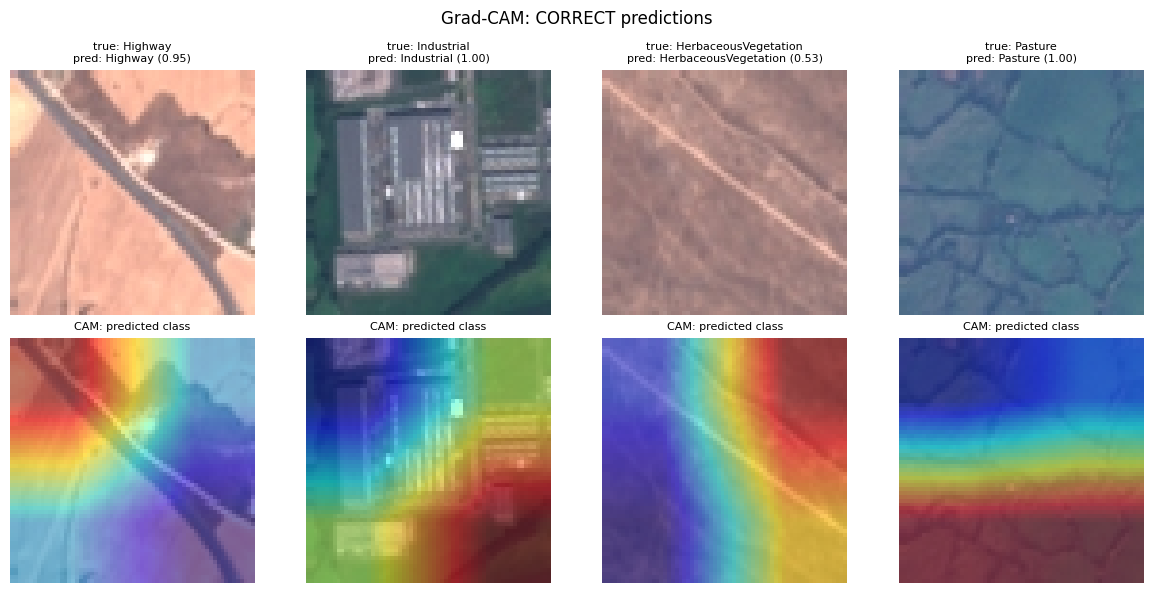

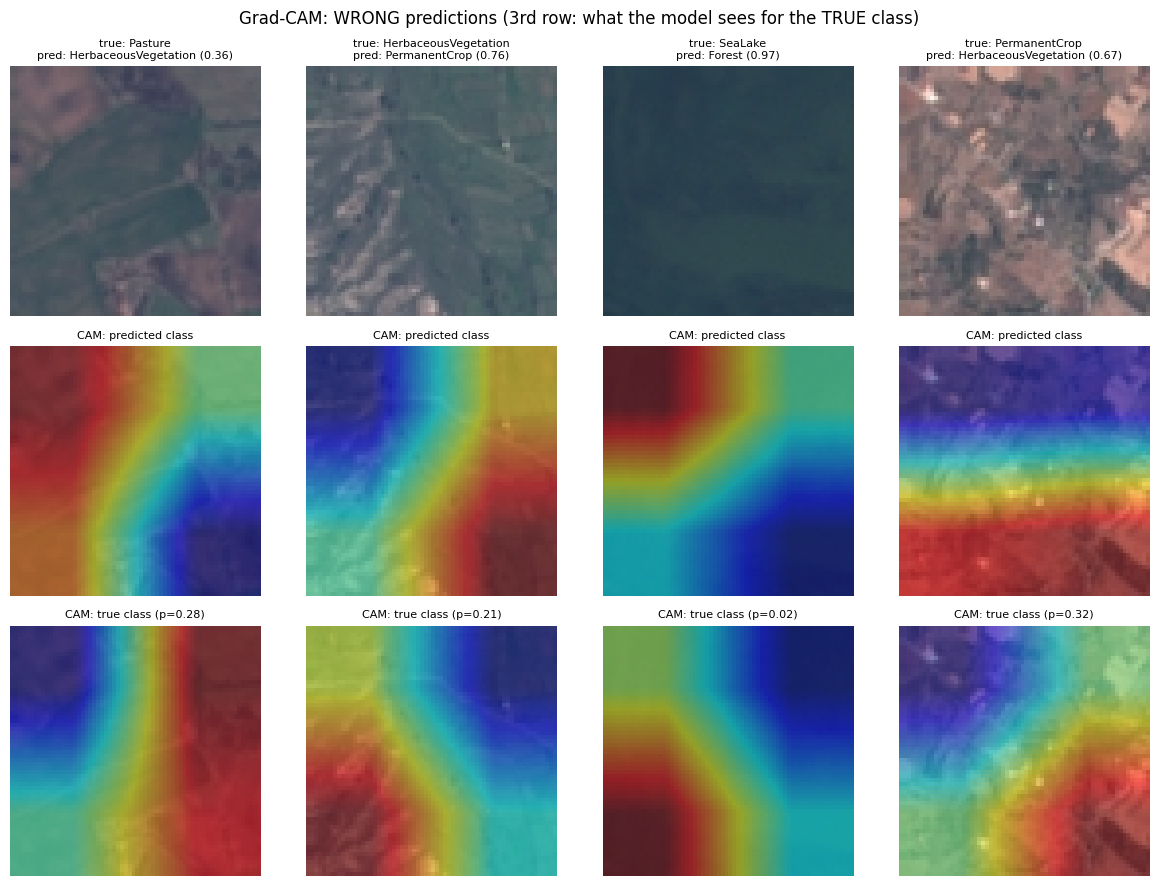

In [30]:
# ---- 4 верных и 4 ошибочных предсказания финальной модели ----
_, _, preds_final = evaluate(final_model, X_test, y_test)
rs = np.random.RandomState(7)
right_idx = rs.permutation(np.where(preds_final == y_test)[0])[:4]
wrong_idx = rs.permutation(np.where(preds_final != y_test)[0])[:4]
print(f"верных найдено: {len(right_idx)}, ошибочных найдено: {len(wrong_idx)} (из {len(y_test)})")

def show_cam_grid(idxs, title, show_true_class_cam=False):
    n = len(idxs)
    if n == 0:
        print("нет примеров для:", title); return
    rows = 3 if show_true_class_cam else 2
    fig, axes = plt.subplots(rows, n, figsize=(3 * n, 3 * rows), squeeze=False)
    for j, i in enumerate(idxs):
        img = X_test[i]
        cam, pred, prob = grad_cam(final_model, img)                       # CAM для ПРЕДСКАЗАННОГО класса
        axes[0, j].imshow(img)
        axes[0, j].set_title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[pred]} ({prob:.2f})", fontsize=8)
        axes[1, j].imshow(overlay(img, cam)); axes[1, j].set_title("CAM: predicted class", fontsize=8)
        if show_true_class_cam:                                            # CAM для ИСТИННОГО класса
            cam_t, _, prob_t = grad_cam(final_model, img, class_idx=y_test[i])
            axes[2, j].imshow(overlay(img, cam_t)); axes[2, j].set_title(f"CAM: true class (p={prob_t:.2f})", fontsize=8)
    for a in axes.ravel(): a.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

show_cam_grid(right_idx, "Grad-CAM: CORRECT predictions")
show_cam_grid(wrong_idx, "Grad-CAM: WRONG predictions (3rd row: what the model sees for the TRUE class)", show_true_class_cam=True)

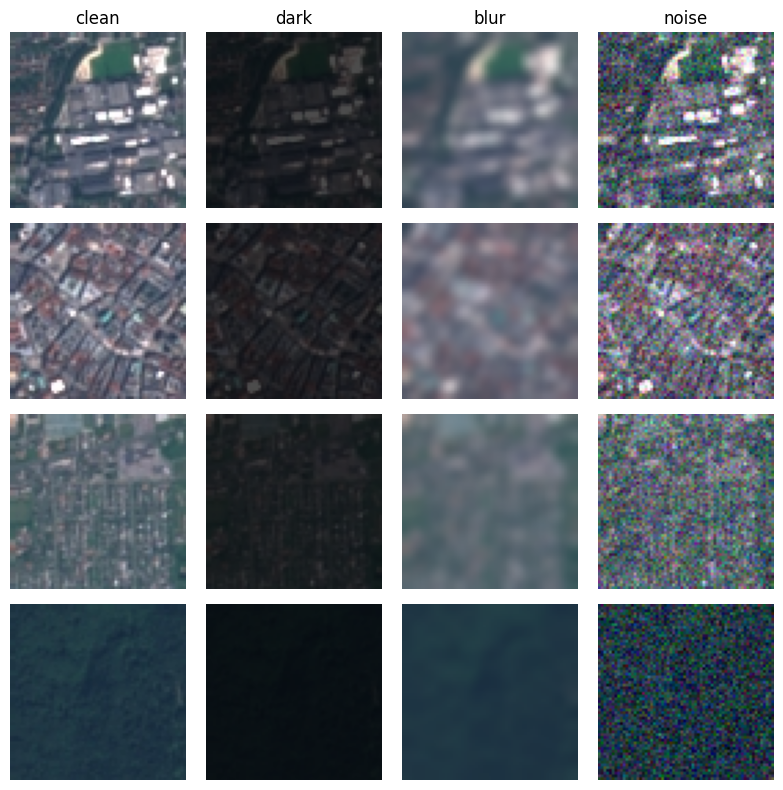

In [31]:
noise_rng = np.random.RandomState(123)

def darken(img, factor=0.3):
    return cv2.convertScaleAbs(img, alpha=factor, beta=0)          # пиксель * 0.3  (ночь/тень)   🔧 factor: меньше = темнее

def blur(img, k=7, sigma=2.0):
    return cv2.GaussianBlur(img, (k, k), sigma)                    # размытие (расфокус)         🔧 k, sigma: больше = сильнее

def add_noise(img, sigma=25):
    noisy = img.astype(np.float32) + noise_rng.normal(0, sigma, img.shape)
    return np.clip(noisy, 0, 255).astype(np.uint8)                 # гауссов шум                 🔧 sigma: больше = шумнее

corruptions = {"clean": lambda im: im, "dark": darken, "blur": blur, "noise": add_noise}
test_sets = {name: np.stack([fn(im) for im in X_test]) for name, fn in corruptions.items()}

# покажем, как это выглядит
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
ex = np.random.RandomState(5).choice(len(X_test), 4, replace=False)
for r, i in enumerate(ex):
    for c, name in enumerate(corruptions):
        axes[r, c].imshow(test_sets[name][i]); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(name)
plt.tight_layout(); plt.show()

### 🔍 Разбор
Все три искажения сделаны **OpenCV/numpy**, как требует условие:
- **`darken`**: `cv2.convertScaleAbs(img, alpha=0.3, beta=0)` = `|img·alpha + beta|` в диапазоне 0–255 → картинка в ~3 раза темнее (ночь, тень).
- **`blur`**: `cv2.GaussianBlur(img, (7,7), 2.0)` — размытие ядром 7×7, `sigma` — сила. Имитирует расфокус/смаз; теряются мелкие детали.
- **`add_noise`**: к картинке (в `float32`, иначе `uint8` переполнится) добавляем нормальный шум `N(0, 25)`, `np.clip(0,255)` и `astype(uint8)` возвращают в допустимый вид. Имитирует шумную камеру.
- `noise_rng` с фиксированным seed → шум одинаков при перезапуске.
- **`corruptions`** — словарь «название → функция» (`lambda im: im` = «ничего»). Для каждой строим искажённую копию всего теста (`np.stack` склеивает список обратно в массив); исходный `X_test` не портим.
- Картинка 4×4: слева направо — чистая, тёмная, размытая, шумная.

In [32]:
def eval_corruptions(model):
    return {name: accuracy_score(y_test, predict(model, Xc)) for name, Xc in test_sets.items()}

acc_final = eval_corruptions(final_model)
table_E = pd.DataFrame({f"final model ({final_name})": acc_final}).T
display(table_E.round(4))

,clean,dark,blur,noise
final model (plain),0.9602,0.5546,0.3269,0.1481


### 🔍 Разбор
- `eval_corruptions` прогоняет модель через 4 набора (clean + 3 искажения) и возвращает accuracy → именно эти числа нужны в отчёте.
- Ожидаемо: на `clean` — как раньше; на искажённых — падение. Модель училась на «хороших» картинках, а мы подсунули данные из *другого распределения* (**distribution shift**): темнота сдвигает пиксели далеко от обучающего диапазона, размытие убирает высокие частоты (мелкие детали, цифры, текстуры), шум добавляет случайные высокочастотные «признаки».
- Обычно сильнее всего страдает один из них — прокомментируй, какой и почему.

In [33]:
# ---- Исправление (fix): обучаем с аугментациями, имитирующими эти искажения ----
robust_loader, robust_crit = make_strategy(final_name, robust=True)
set_seed()
model_rob = build_model()
model_rob, hist_rob = fit(model_rob, robust_loader, val_loader, robust_crit, name="robust-aug")

acc_rob = eval_corruptions(model_rob)
table_E = pd.DataFrame({f"final model ({final_name})": acc_final, "retrained with robust aug": acc_rob}).T
display(table_E.round(4))
table_E.T.plot(kind="bar", figsize=(9, 4), ylim=(0, 1.05), rot=0)
plt.ylabel("test accuracy"); plt.title("Accuracy under corruptions: before / after fix"); plt.grid(axis="y", alpha=.3)
plt.show()

torch.save(final_model.state_dict(), "final_model.pt")

NameError: name 'make_strategy' is not defined

### 🔍 Разбор
**Предлагаемое исправление: аугментация данных, имитирующая реальные помехи.** Если модель на обучении видела тёмные, размытые и шумные версии, в реальности она не растеряется.
- `make_strategy(final_name, robust=True)` включает усиленный режим: `ColorJitter(brightness=(0.2,1.3), contrast=(0.5,1.3))` — затемнение до 20 % яркости; `GaussianBlur(5, sigma=0.1–2)` с вероятностью 30 %; гауссов шум с вероятностью 30 %.
- Обучаем новую модель тем же кодом, сравниваем таблицей «до / после» и столбчатой диаграммой. Качество на искажённых выросло, а на clean почти не упало → fix работает.
- ⚠️ `fit` выбирает лучшую эпоху по чистой val-выборке; идеальнее мерить и на искажённой — упомяни как возможное улучшение.
- `torch.save(...state_dict(), "final_model.pt")` — сохраняем веса финальной модели.

**Другие варианты fix (достаточно предложить ОДИН, но знай и другие):**
- *Предобработка на входе:* выравнивание гистограммы / **CLAHE** (`cv2.createCLAHE`) для тёмных картинок; шумоподавление (`cv2.fastNlMeansDenoisingColored`, медианный фильтр); нерезкая маска (unsharp mask) для размытия.
- *Аппаратно/системно:* HDR или ИК-камера, усреднение по нескольким кадрам видео.
- *Адаптация на тесте:* нормализация яркости каждой картинки по её собственной статистике.

# Report skeleton (1–2 pages PDF) — заполни числами из своих запусков

**Goal.** Build a classifier for **K** classes (dataset: ____, image size IMG×IMG, N training images) and test it under class imbalance and bad imaging conditions.

**Method.** Data split: train / val / test (sizes). Augmentation: rotation, translation, scale, brightness/contrast; flip used / not used because ____. Model: ____ (**X params**; chosen because ____). Adam, lr ____, cosine schedule, ____ epochs.

**Results (table):** accuracy / macro-F1 for each strategy; accuracy for clean / dark / blur / noise before and after the fix. Figures: class distribution, training curves, confusion matrix (top-10), corruption examples.

**Analysis (one paragraph).** (1) Overall quality; (2) worst 3 classes and why (rare / visually similar); (3) effect of the imbalance strategy on macro-F1 vs accuracy (and whether it exceeds seed noise); (4) which corruption hurts most and why; (5) effect of the fix and remaining limitations.

**Who did what.** Student 1: data pipeline & visualization; Student 2: model, training, Part D; Student 3: evaluation, robustness, report.

# Вероятные вопросы на устной защите

1. **Безопасен ли horizontal flip для твоих данных? Почему?** Зависит от того, меняет ли зеркало класс/смысл (знаки left/right, цифры — нет; одежда, животные — можно).
2. **Зачем нормализация и почему статистика только по train?** Ускоряет и стабилизирует обучение; статистика по test — утечка информации.
3. **Что делает свёртка / BatchNorm / ReLU / MaxPool / GAP?** См. азбуку в начале.
4. **Зачем `model.eval()` и `torch.no_grad()`?** eval выключает Dropout и «замораживает» BatchNorm; no_grad не считает градиенты — быстрее и меньше памяти.
5. **Что делают `zero_grad`, `backward`, `step`?** Стереть старые градиенты → посчитать новые → обновить веса.
6. **Что такое переобучение? Как увидеть?** train ≫ val; val loss растёт. Борьба: аугментация, Dropout, weight decay, меньше эпох/параметров, больше данных.
7. **Accuracy vs macro-F1?** Accuracy доминируют частые классы; macro-F1 даёт каждому классу равный вес и замечает провал на редких.
8. **Формулы recall / precision / F1?** `recall = correct_c / true_c`; `precision = correct_c / predicted_c`; `F1 = 2PR/(P+R)`.
9. **Как читать confusion matrix?** Строка — истина, столбец — предсказание; диагональ — верно; вне диагонали — путаница конкретных классов.
10. **Как работает class-weighted loss и oversampling?** Вес ошибки обратно пропорционален частоте / редкие картинки чаще попадают в батчи. Weighted не меняет данные; oversampling рискует запоминанием редких картинок.
11. **Почему такая модель (своя CNN / предобученная)?** Размер, скорость, задача, размер картинок; fine-tuning — когда мало данных/сложная задача.
12. **Зачем val, если есть test?** Val — выбор эпохи/модели; test — единственная честная финальная оценка, на нём ничего не подбирали.
13. **Почему модель ломается на тёмных/размытых/шумных данных? Что исправить?** Distribution shift; аугментация с такими искажениями (или CLAHE / денойзинг на входе).
14. **Что такое `padding`, `stride`, `kernel_size`?** Рамка нулей (сохраняет размер) / шаг фильтра / размер окна свёртки.
15. **Что такое batch и epoch?** Порция картинок за один шаг / полный проход по train.
16. **Как подключить новый датасет?** Свести к `ds[i] -> (картинка, класс)`; привести картинку к `(H,W,3) uint8 RGB` (`to_rgb_uint8`); ресайз; дальше всё работает на numpy-массивах.

---
## Чек-лист перед сдачей
- [ ] Имена в первой ячейке
- [ ] `Runtime → Restart and run all` — всё проходит сверху вниз, все выводы видны
- [ ] Отчёт PDF 1–2 страницы (цель, метод, таблицы/рисунки, абзац анализа, кто что делал)
- [ ] Загружено в Moodle до окончания 120 минут (штраф −10 баллов за каждые 5 минут опоздания)
- [ ] Каждый умеет объяснить любую ячейку